# Scan Beras

Baru-baru ini, para ilmuwan mengidentifikasi sebuah **varian jamur berbahaya** yang dapat tumbuh di dalam biji beras. Jamur ini sulit dideteksi secara visual karena bagian luar beras dapat terlihat normal, sementara infeksi berkembang di bagian dalam.

Untuk mendeteksi keberadaan jamur tanpa merusak biji beras, setiap sampel dipindai menggunakan teknologi pencitraan menyerupai **MRI/CT scan**. Setiap biji beras direpresentasikan sebagai sekumpulan gambar irisan (*slice*) 2D yang secara keseluruhan membentuk struktur 3D dari biji tersebut.

Tugas Anda adalah menganalisis hasil pemindaian tersebut dan menentukan:

1. **Lokasi area yang terinfeksi jamur** pada setiap irisan scan.
2. **Volume total infeksi** di dalam setiap biji beras dalam satuan **mm³**.


# Deskripsi Dataset

Setiap sampel adalah volume 3D yang tersusun dari 72 citra grayscale berukuran
128×128. Folder `kaggle_data/` berisi:

- `train.csv`: kolom `id`, `scan_path`, `mask_path`, `pixel_spacing_mm`,
  `n_slices`, dan `defect_volume_mm3`;
- `test.csv`: kolom yang sama tanpa mask dan volume target;
- `scans/train/` serta `scans/test/`: irisan scan;
- `masks/train/`: mask biner cacat untuk data training;
- `sample_submission.csv`: template kolom keluaran.

Kolom `segmentation` pada submission menggunakan Run-Length Encoding (RLE)
mask 3D, sedangkan `defect_volume_mm3` berisi estimasi volume dalam mm³.


# Evaluasi

Skor akhir merupakan gabungan dua komponen dengan bobot sama:

1. rata-rata **Dice Score** antara mask prediksi dan mask benar;
2. akurasi volume ternormalisasi, yaitu
   `clip(1 - MAE / mean(abs(volume_benar)), 0, 1)`.

Skor akhir adalah `0.5 × mean_Dice + 0.5 × akurasi_volume` dan nilai yang
lebih tinggi lebih baik.


## Memuat Data Kaggle (Tidak Perlu Diubah)


In [1]:
from pathlib import Path

def cari_folder_data(berkas_wajib):
    """Cari folder dataset pada komputer lokal atau Kaggle."""
    kandidat = [Path("kaggle_data"), Path("../kaggle_data"), Path(".")]
    folder_kaggle = Path("/kaggle/input")
    if folder_kaggle.exists():
        kandidat.extend(path.parent for path in folder_kaggle.rglob(berkas_wajib))
    for folder in kandidat:
        if (folder / berkas_wajib).exists() and (folder / "sample_submission.csv").exists():
            return folder
    raise FileNotFoundError(f"Dataset Kaggle dengan berkas {berkas_wajib} tidak ditemukan")




DATA_DIR = cari_folder_data("test.csv")
print("Folder data:", DATA_DIR.resolve())


Folder data: /kaggle/input/competitions/soal-1-3-final-ekka-2026/kaggle_data


## Fungsi Bantu (Tidak Perlu Diubah)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_opening, binary_closing

try:
    import cv2
except ImportError:
    cv2 = None
    print("OpenCV tidak tersedia; pemuatan citra memakai PIL.")


In [3]:
def load_data(data_dir=DATA_DIR, fraksi_validasi=0.2):
    """Muat data dan sisihkan sebagian training untuk validasi lokal."""
    semua_train = pd.read_csv(data_dir / "train.csv")
    test = pd.read_csv(data_dir / "test.csv")
    sample_submission = pd.read_csv(
        data_dir / "sample_submission.csv", keep_default_na=False
    )
    rng = np.random.default_rng(2026)
    urutan = rng.permutation(len(semua_train))
    batas = int((1.0 - fraksi_validasi) * len(semua_train))
    train = semua_train.iloc[urutan[:batas]].reset_index(drop=True)
    val = semua_train.iloc[urutan[batas:]].reset_index(drop=True)
    return train, val, test, sample_submission


In [50]:
# Muat dan tampilkan irisan scan beras.
def load_scan(row, data_dir=DATA_DIR):
    folder_scan = data_dir / row["scan_path"]
    jalur_irisan = sorted(folder_scan.glob("slice_*.png"))
    gambar = []
    for path in jalur_irisan:
        if cv2 is not None:
            image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        else:
            image = np.asarray(Image.open(path).convert("L"))
        if image is None:
            raise ValueError(f"Tidak dapat membaca {path}")
        gambar.append(image)
    return np.stack(gambar)


def plot_slices(scan, indices=None, n=6):
    if indices is None:
        indices = np.linspace(0, len(scan) - 1, n, dtype=int)
    indices = list(indices)
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3))
    if len(indices) == 1:
        axes = [axes]
    for ax, z in zip(axes, indices):
        ax.imshow(scan[z], cmap="gray")
        ax.set_title(f"Irisan {z}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [5]:
def rle_encode(mask):
    """Ubah mask biner 3D menjadi string Run-Length Encoding."""
    piksel = np.asarray(mask, dtype=np.uint8).reshape(-1)
    berlapis = np.concatenate([[0], piksel, [0]])
    perubahan = np.where(berlapis[1:] != berlapis[:-1])[0] + 1
    awal = perubahan[::2]
    akhir = perubahan[1::2]
    panjang = akhir - awal
    encoded = " ".join(f"{mulai} {lama}" for mulai, lama in zip(awal, panjang))
    return encoded or "0"


In [6]:
def load_mask(row, data_dir=DATA_DIR):
    """Muat seluruh irisan mask biner untuk satu sampel."""
    folder_mask = data_dir / row["mask_path"]
    paths = sorted(folder_mask.glob("slice_*.png"))
    masks = []
    for path in paths:
        if cv2 is not None:
            mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        else:
            mask = np.asarray(Image.open(path).convert("L"))
        if mask is None:
            raise ValueError(f"Tidak dapat membaca {path}")
        masks.append(mask > 0)
    return np.stack(masks)


In [7]:
def predict_all(df, data_dir=DATA_DIR):
    """Jalankan fungsi predict untuk seluruh baris dataframe."""
    mask_prediksi, segmentasi, volume = [], [], []
    for _, row in df.iterrows():
        pred_mask, pred_volume = predict(row, data_dir=data_dir)
        mask_prediksi.append(pred_mask)
        segmentasi.append(rle_encode(pred_mask))
        volume.append(pred_volume)
    return mask_prediksi, segmentasi, np.asarray(volume)


In [8]:
def dice_score(y_true, y_pred):
    """Hitung Dice Score untuk dua mask biner."""
    y_true = np.asarray(y_true, dtype=bool)
    y_pred = np.asarray(y_pred, dtype=bool)
    irisan = np.sum(y_true & y_pred)
    jumlah = np.sum(y_true) + np.sum(y_pred)
    if jumlah == 0:
        return 1.0
    return 2.0 * irisan / jumlah


In [9]:
def evaluate(df, pred_masks, pred_volumes, data_dir=DATA_DIR):
    """Evaluasi Dice dan MAE pada bagian training yang disisihkan."""
    skor_dice = []
    for i, (_, row) in enumerate(df.iterrows()):
        mask_benar = load_mask(row, data_dir)
        skor_dice.append(dice_score(mask_benar, pred_masks[i]))
    volume_benar = np.asarray(df["defect_volume_mm3"])
    volume_prediksi = np.asarray(pred_volumes)
    rata_dice = np.mean(skor_dice)
    mae = np.mean(np.abs(volume_benar - volume_prediksi))
    print(f"Dice: {rata_dice:.4f}")
    print(f"MAE  : {mae:.6f}")
    return {"dice": rata_dice, "mae": mae}


In [11]:
def make_submission(test, segmentations, volumes, sample_submission,
                    filename="submission.csv"):
    """Buat file submission dengan urutan ID dari template Kaggle."""
    prediksi = pd.DataFrame({
        "id": test["id"],
        "segmentation": segmentations,
        "defect_volume_mm3": volumes,
    })
    submission = sample_submission[["id"]].merge(prediksi, on="id", how="left")
    if submission.isna().any().any():
        raise ValueError("Ada sampel uji yang belum memiliki prediksi")
    submission.to_csv(filename, index=False)
    return submission


# Baseline


In [12]:
train, val, test, sample_submission = load_data()
display(train.head())
display(test.head())
print("Bentuk train/validasi/test:", train.shape, val.shape, test.shape)


,id,scan_path,mask_path,pixel_spacing_mm,n_slices,defect_volume_mm3
0,train_0066,scans/train/train_0066,masks/train/train_0066,0.04,72,0.037600
1,train_0045,scans/train/train_0045,masks/train/train_0045,0.04,72,0.169984
2,train_0048,scans/train/train_0048,masks/train/train_0048,0.04,72,0.063360
3,train_0017,scans/train/train_0017,masks/train/train_0017,0.04,72,0.172032
4,train_0018,scans/train/train_0018,masks/train/train_0018,0.04,72,0.034880


,id,scan_path,pixel_spacing_mm,n_slices
0,val_0001,scans/test/val_0001,0.04,72
1,val_0002,scans/test/val_0002,0.04,72
2,val_0003,scans/test/val_0003,0.04,72
3,val_0004,scans/test/val_0004,0.04,72
4,val_0005,scans/test/val_0005,0.04,72


Bentuk train/validasi/test: (72, 6) (18, 6) (60, 4)


In [34]:
train.head(4)

,id,scan_path,mask_path,pixel_spacing_mm,n_slices,defect_volume_mm3
0,train_0066,scans/train/train_0066,masks/train/train_0066,0.04,72,0.037600
1,train_0045,scans/train/train_0045,masks/train/train_0045,0.04,72,0.169984
2,train_0048,scans/train/train_0048,masks/train/train_0048,0.04,72,0.063360
3,train_0017,scans/train/train_0017,masks/train/train_0017,0.04,72,0.172032


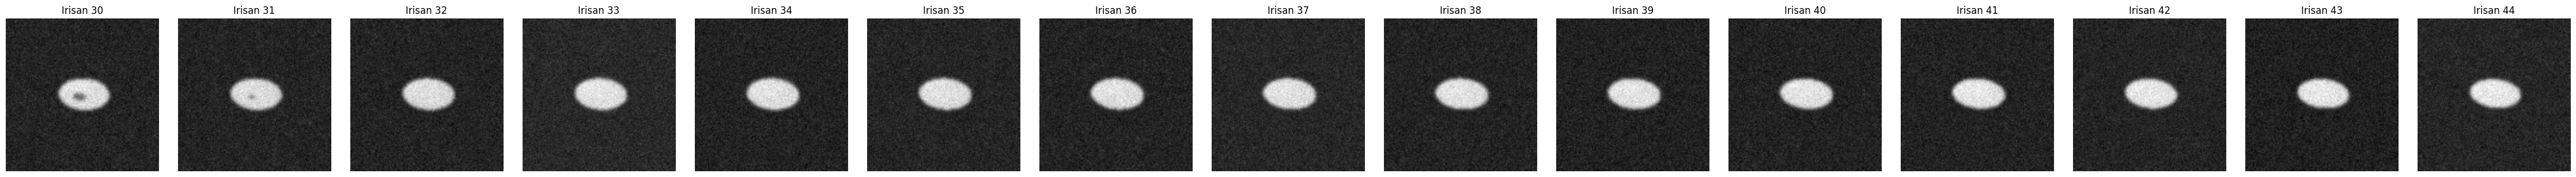

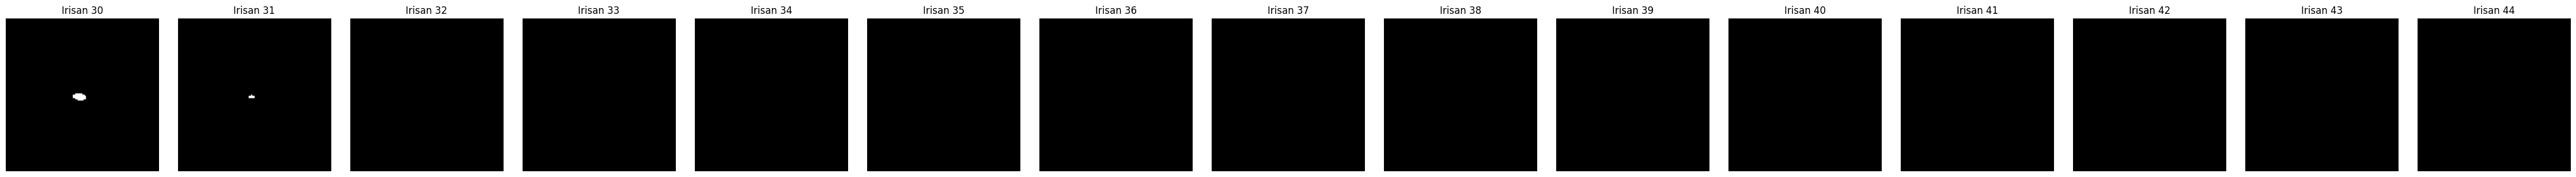

id                               train_0017
scan_path            scans/train/train_0017
mask_path            masks/train/train_0017
pixel_spacing_mm                       0.04
n_slices                                 72
defect_volume_mm3                  0.172032
Name: 3, dtype: object


In [51]:
# dapat dilihat bahwa terdapat bintik gelap pada slice 33 sampai 42 pada beras ini
scan = load_scan(
    train.iloc[3]
)

plot_slices(
    scan,
    indices=range(30, 45)
)

true_mask = load_mask(
    train.iloc[3]
)

plot_slices(true_mask.astype(np.uint8) * 255, indices=range(30, 45))
print(train.iloc[3])

In [127]:
# Fungsi segmentasi butir beras untuk baseline.
def segment_rice(scan):
    masks = []
    struktur = np.ones((3, 3), dtype=bool)
    for image in scan:
        # Pisahkan bagian beras yang lebih terang dari latar belakang.
        _, mask = cv2.threshold(
            image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
        # c, _ = cv2.findContours(mask, np.ones((3,3)))
        # c_sorted = np.max(c, lambda key: cv2.contourArea)
        # mask = c_sorted[0]
        # kernel = np.ones((3, 3), np.uint8)
        # mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        # mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        # mask = mask > 0
        # masks.append(mask)
        ans = []
        offset = 3
        for i in range(128):
            ls = []
            for j in range(128):
                if i <= 64+offset and i >= 64-offset and j <= 64+offset and j >= 64-offset:
                    ls.append(True)
                else:
                    ls.append(False)
            ans.append(ls)
        masks.append(ans)
    return np.stack(masks)


(72, 128, 128)


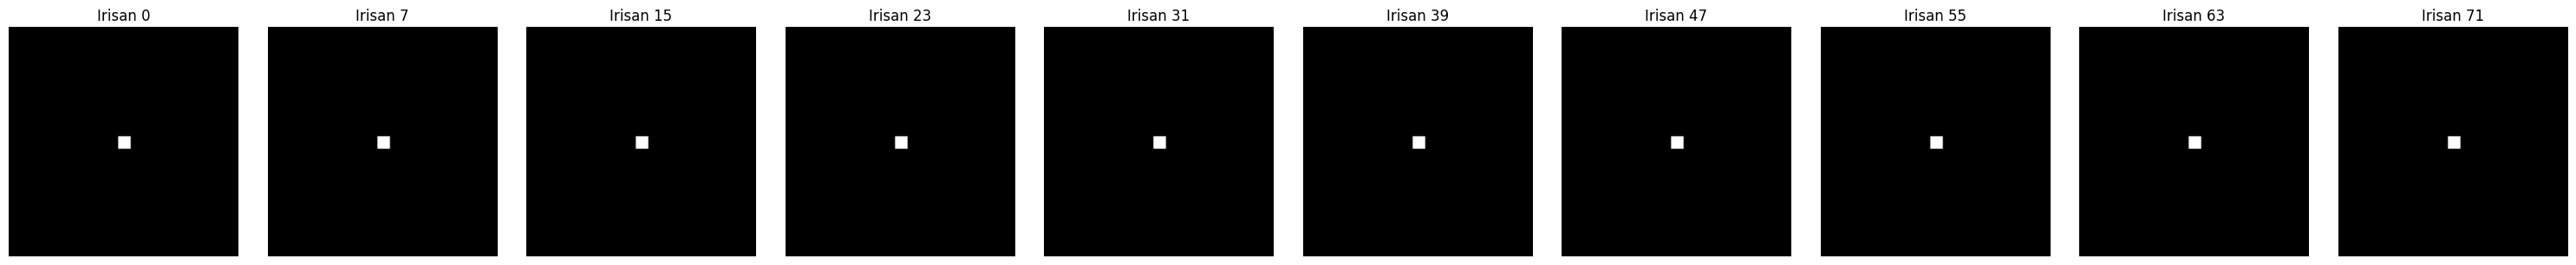

In [128]:
scan = load_scan(train.iloc[3])
rice_mask = segment_rice(scan)

print(rice_mask.shape)

plot_slices(rice_mask.astype(np.uint8) * 255, n=10)


In [129]:
# Anda perlu mengubah fungsi ini.

def predict(row, data_dir=DATA_DIR):
    scan = load_scan(
        row,
        data_dir
    )

    # Baseline memakai mask butir beras dan jarak antarslice tetap
    pred_mask = segment_rice(scan)

    slice_spacing_mm = 0.5

    pixel_spacing_mm = float(
        row["pixel_spacing_mm"]
    )

    voxel_volume_mm3 = (
        pixel_spacing_mm
        * pixel_spacing_mm
        * slice_spacing_mm
    )

    volume = (
        np.sum(pred_mask)
        * voxel_volume_mm3
    )

    return pred_mask, 0.2


In [130]:
pred_mask, pred_volume = predict(
    val.iloc[0]
)

print(pred_mask.shape)
print("Volume:", pred_volume)


(72, 128, 128)
Volume: 0.2


In [131]:
val_masks, val_segmentations, val_volumes = (
    predict_all(val)
)

metrics = evaluate(
    val,
    val_masks,
    val_volumes
)


Dice: 0.0461
MAE  : 0.140487


In [132]:
test_masks, test_segmentations, test_volumes = predict_all(test)
submission = make_submission(
    test,
    test_segmentations,
    test_volumes,
    sample_submission,
    "submission8.csv"
)
display(submission.head())


,id,segmentation,defect_volume_mm3
0,val_0001,7870 7 7998 7 8126 7 8254 7 8382 7 8510 7 8638...,0.2
1,val_0002,7870 7 7998 7 8126 7 8254 7 8382 7 8510 7 8638...,0.2
2,val_0003,7870 7 7998 7 8126 7 8254 7 8382 7 8510 7 8638...,0.2
3,val_0004,7870 7 7998 7 8126 7 8254 7 8382 7 8510 7 8638...,0.2
4,val_0005,7870 7 7998 7 8126 7 8254 7 8382 7 8510 7 8638...,0.2
